# Predicting Food Prices in Sri Lanka: Random Forest vs XGBoost vs Stacking
**Class activity: ML Lecture 7 (ensemble methods)**

**Problem (regression):** predict the price (LKR per unit) of a food item at a Sri Lankan market from the commodity, market, region, price type, year and month.
**Dataset:** WFP Food Prices for Sri Lanka (via the Humanitarian Data Exchange), monthly market prices, 2004-2025.
**Why it matters locally:** food price inflation (especially after 2022) directly affects households, so a model that estimates expected prices helps with budgeting and spotting unusual market prices.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pickle
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
import pipeline as P
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
raw = pd.read_csv(P.DATA, parse_dates=["date"])
print(raw.shape); raw.head()

(32496, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.71,0.33
1,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.66,0.27
2,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,33.62,0.34
3,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.71,0.27
4,2004-03-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.92,0.34


## 1. Data understanding and null detection

In [2]:
print(raw.dtypes.to_string()); print()
nulls = raw.isna().sum(); print("Null values per column:\n", nulls[nulls > 0].to_string())
print("\nDuplicate rows:", raw.duplicated().sum())
print("\nConstant columns:", [c for c in raw.columns if raw[c].nunique() == 1])
print("\nMarket(s) of the 194 rows with missing region:", list(raw[raw.admin1.isna()].market.unique()))

date            datetime64[us]
admin1                     str
admin2                     str
market                     str
market_id                int64
latitude               float64
longitude              float64
category                   str
commodity                  str
commodity_id             int64
unit                       str
priceflag                  str
pricetype                  str
currency                   str
price                  float64
usdprice               float64

Null values per column:
 admin1       194
admin2       194
latitude     194
longitude    194

Duplicate rows: 0

Constant columns: ['priceflag', 'currency']

Market(s) of the 194 rows with missing region: ['National Average']


**Findings.** Only 194 rows (all from the "National Average" pseudo-market) lack region and coordinates. `priceflag` and `currency` never change, so they carry no information. `usdprice` is just `price` divided by an exchange rate, so using it would **leak the target**, and `market_id`/`commodity_id` duplicate the name columns.

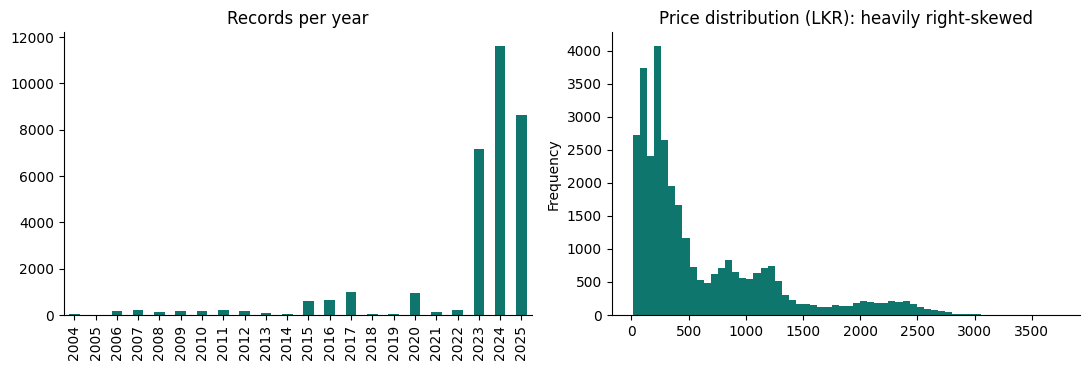

count    32496.0
mean       609.7
std        626.9
min         11.5
25%        180.5
50%        340.0
75%        888.6
max       3735.4


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
raw.groupby(raw.date.dt.year).size().plot.bar(ax=ax[0], color="#0F766E"); ax[0].set_title("Records per year"); ax[0].set_xlabel("")
raw.price.plot.hist(bins=60, ax=ax[1], color="#0F766E"); ax[1].set_title("Price distribution (LKR): heavily right-skewed"); plt.tight_layout(); plt.show()
print(raw.price.describe().round(1).to_string())

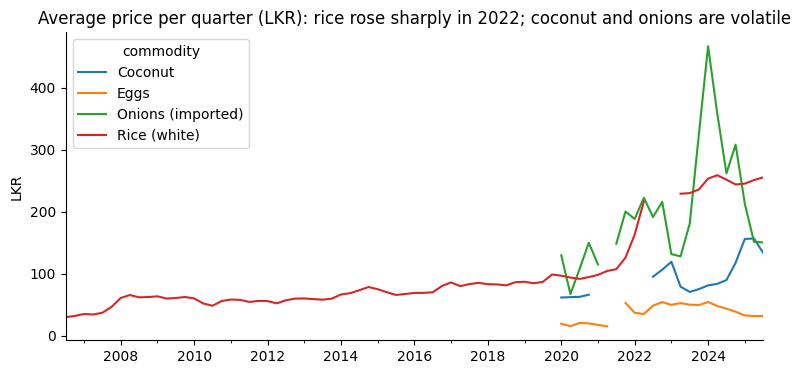

Outliers by IQR rule (overall): 2158 -> almost all are fish items (sail fish, dried katta, tuna), which are genuinely expensive, not errors, so they are kept.


In [4]:
top = ["Rice (white)", "Eggs", "Coconut", "Onions (imported)"]
(raw[raw.commodity.isin(top)].groupby([raw.date.dt.to_period("Q").dt.to_timestamp(), "commodity"]).price.mean().unstack()
 .plot(figsize=(9, 4), title="Average price per quarter (LKR): rice rose sharply in 2022; coconut and onions are volatile")); plt.ylabel("LKR"); plt.xlabel(""); plt.show()
q1, q3 = raw.price.quantile([.25, .75]); iqr = q3 - q1
print("Outliers by IQR rule (overall):", int(((raw.price > q3 + 1.5 * iqr)).sum()),
      "-> almost all are fish items (sail fish, dried katta, tuna), which are genuinely expensive, not errors, so they are kept.")

## 2. Preprocessing (implemented in `pipeline.py`)
| Step | What and why |
|---|---|
| Drop leaky/redundant columns | `usdprice` (leakage), ids, constants, `admin2` (redundant with market and coordinates) |
| Date features | `date` becomes `year` and `month` so trees can learn trend and seasonality |
| Imputation | Missing `admin1` becomes "Unknown"; missing latitude/longitude are filled with the **median** (inside the pipeline, fitted on training data only) |
| Encoding | One-hot encoding for commodity, category, unit, price type, market, region (unknown categories are ignored at inference) |
| Scaling | `StandardScaler` on numeric features. Trees do not need it, but it keeps the pipeline reusable for distance/gradient models |
| Target transformation | Prices range from about 11 to 3,700 LKR, so models are trained on `log1p(price)` and predictions are converted back with `expm1`. This treats a 10% error the same on cheap and expensive items |
| Splitting | **Time-based:** train on 2004-2024, test on 2025. One row from the newest month is held out first for single-sample inference |

In [5]:
df = P.load_clean()
hold = df[df.date == df.date.max()].sample(1, random_state=7); df = df.drop(hold.index)
Xtr, Xte, ytr, yte = P.split(df)
print("Train:", Xtr.shape, " Test:", Xte.shape, " Held-out sample:", hold.shape)
Xtr.head()

Train: (23868, 10)  Test: (8627, 10)  Held-out sample: (1, 12)


,commodity,category,unit,pricetype,market,admin1,latitude,longitude,year,month
0,Rice (red nadu),cereals and tubers,KG,Retail,Colombo City,Western,6.93,79.85,2004,1
1,Wheat flour,cereals and tubers,KG,Retail,Colombo City,Western,6.93,79.85,2004,1
2,Rice (red nadu),cereals and tubers,KG,Retail,Colombo City,Western,6.93,79.85,2004,2
3,Wheat flour,cereals and tubers,KG,Retail,Colombo City,Western,6.93,79.85,2004,2
4,Rice (red nadu),cereals and tubers,KG,Retail,Colombo City,Western,6.93,79.85,2004,3


## 3. Parameter design (no defaults)
**Random Forest** (bagging: many deep trees on bootstrap samples, averaged)
- `n_estimators=300`: enough trees for the variance reduction to level off, without wasting time.
- `max_depth=20`: prices depend on interactions (commodity x market x time), so trees must go deep; capped to limit memorising noise.
- `min_samples_leaf=3`: stops leaves fitting single noisy observations.
- `max_features=0.5`: each split sees half the (one-hot expanded) features, which decorrelates trees.

**XGBoost** (boosting: shallow trees added one at a time, each correcting the previous errors)
- `learning_rate=0.05` with `n_estimators=600`: small steps with many rounds generalise better than a few big steps.
- `max_depth=6`: boosting works best with shallower trees than a forest because errors are corrected step by step.
- `subsample=0.8`, `colsample_bytree=0.7`: random row and column sampling for regularisation.
- `min_child_weight=3`, `reg_lambda=2`: stop tiny leaves and shrink leaf values (L2 penalty).

**Stacking:** Random Forest and XGBoost are the base learners. A `RidgeCV` meta-model learns how to weight their out-of-fold predictions (3-fold CV, shuffled so the meta-model sees honest predictions).

## 4. Training and comparison

In [6]:
specs = {"Random Forest": P.rf(), "XGBoost": P.xgb(), "Stacking (RF+XGB)": P.stack()}
models, preds, rows = {}, {}, []
for name, est in specs.items():
    m = P.build(est).fit(Xtr, ytr); p = m.predict(Xte); models[name], preds[name] = m, p
    rows.append({"Model": name, "RMSE (LKR)": np.sqrt(mean_squared_error(yte, p)), "MAE (LKR)": mean_absolute_error(yte, p),
                 "R2": r2_score(yte, p), "MAPE %": np.mean(np.abs(yte - p) / yte) * 100})
res = pd.DataFrame(rows).set_index("Model").round(3); res

,RMSE (LKR),MAE (LKR),R2,MAPE %
Model,,,,
Random Forest,192.960,129.382,0.911,27.539
XGBoost,186.790,125.546,0.917,26.908
Stacking (RF+XGB),187.609,125.822,0.916,27.021


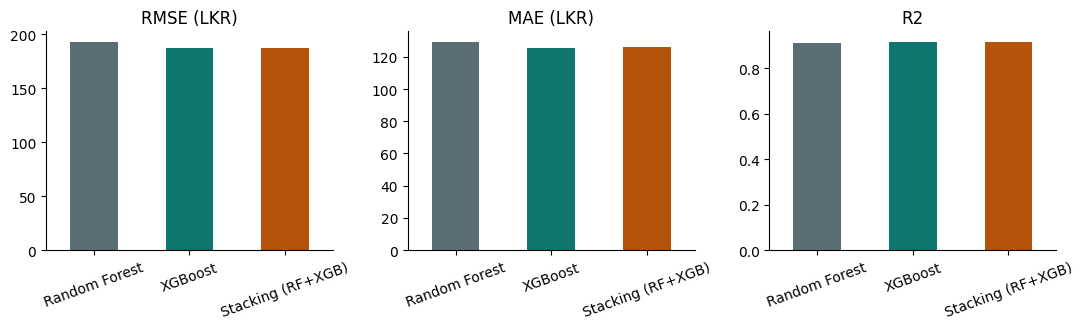

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
for a, c in zip(ax, ["RMSE (LKR)", "MAE (LKR)", "R2"]):
    res[c].plot.bar(ax=a, color=["#5B6E74", "#0F766E", "#B45309"], rot=20); a.set_title(c); a.set_xlabel("")
plt.tight_layout(); plt.show()

## 5. Is the evaluation honest? Random split vs time-based split
Prices trend upward over time, so a random split lets the model "peek" at neighbouring months. This compares the same XGBoost model under both splits.

In [8]:
Xall, yall = df[P.CAT + P.NUM], df[P.TARGET]
Xa, Xb, ya, yb = train_test_split(Xall, yall, test_size=0.26, random_state=0)
pr = P.build(P.xgb()).fit(Xa, ya).predict(Xb)
print(f"Random split R2: {r2_score(yb, pr):.3f}  RMSE: {np.sqrt(mean_squared_error(yb, pr)):.1f}")
print(f"Time split   R2: {res.loc['XGBoost','R2']:.3f}  RMSE: {res.loc['XGBoost','RMSE (LKR)']:.1f}")

Random split R2: 0.978  RMSE: 93.1
Time split   R2: 0.917  RMSE: 186.8


## 6. Interpreting the results

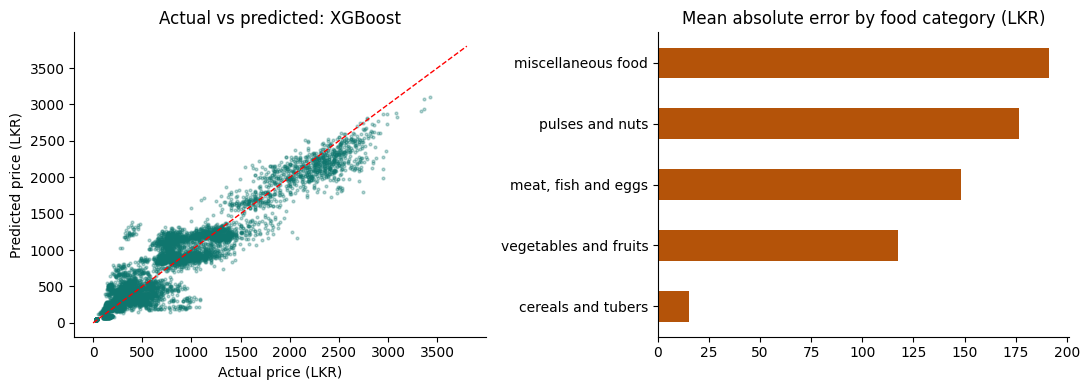

In [9]:
best = res["RMSE (LKR)"].idxmin(); p = preds[best]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(yte, p, s=4, alpha=.3, color="#0F766E"); ax[0].plot([0, 3800], [0, 3800], "r--", lw=1)
ax[0].set(xlabel="Actual price (LKR)", ylabel="Predicted price (LKR)", title=f"Actual vs predicted: {best}")
err = pd.DataFrame({"cat": Xte.category.values, "ae": np.abs(yte.values - p)}).groupby("cat").ae.mean().sort_values()
err.plot.barh(ax=ax[1], color="#B45309"); ax[1].set(title="Mean absolute error by food category (LKR)", ylabel="")
plt.tight_layout(); plt.show()

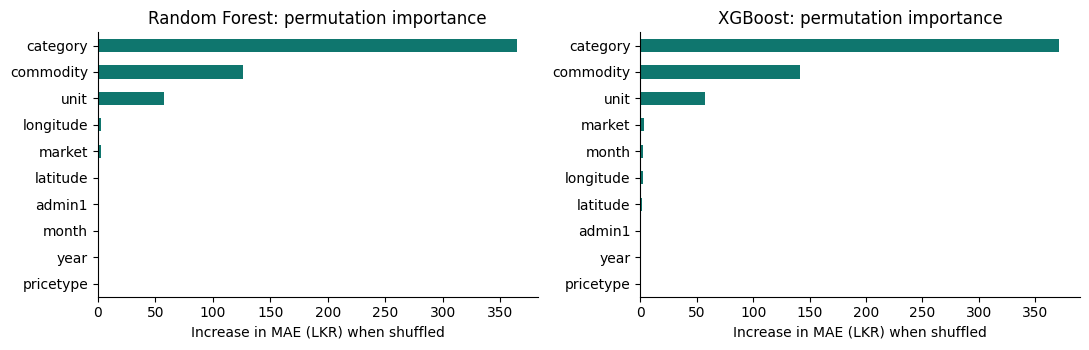

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, n in zip(ax, ["Random Forest", "XGBoost"]):
    s = Xte.sample(3000, random_state=1)
    pi = permutation_importance(models[n], s, yte.loc[s.index], n_repeats=3, random_state=0, scoring="neg_mean_absolute_error")
    pd.Series(pi.importances_mean, index=s.columns).sort_values().plot.barh(ax=a, color="#0F766E"); a.set_title(f"{n}: permutation importance")
    a.set_xlabel("Increase in MAE (LKR) when shuffled")
plt.tight_layout(); plt.show()

### Strengths and limitations of each model
**Random Forest**
- *Strengths:* very robust with little tuning, handles mixed one-hot and numeric features, hard to overfit badly because averaging many trees cuts variance, and trees can be trained in parallel.
- *Limitations:* trees cannot extrapolate beyond the price range seen in training, so it underestimates when prices keep rising (this matters for inflation). It is also larger and slower at inference, and less accurate than boosting when subtle patterns matter.

**XGBoost**
- *Strengths:* sequentially corrects errors, so it captures finer interactions (commodity x market x time). Built-in regularisation and subsampling control overfitting, and it was the most accurate single model here.
- *Limitations:* more hyperparameters to tune, more sensitive to them than a forest, and it can also not extrapolate beyond the training price range.

**Stacking (RF + XGBoost)**
- *Strengths:* learns how much to trust each base model, and usually matches or beats the best single model.
- *Limitations:* more training time and complexity, harder to explain, and the gain is small when base models make similar mistakes (as here, since both are tree ensembles on the same features).

### Interpretation
- XGBoost achieved the lowest error, with Stacking very close and Random Forest slightly behind. The gaps between the models are small compared with the gap between the random split (R2 0.978) and the honest time split (R2 0.917), so how you evaluate matters more than which of these models you pick.
- **Error depends on the food category.** Cereals are very predictable (about 6% average error) because their prices are stable. Vegetables and fruits have the highest percentage error (about 40%) because their prices swing with the season and weather, and this drives the overall MAPE of about 27% even though R2 is 0.92. In rupees, miscellaneous food, pulses and meat/fish have the largest errors, since their prices are higher.
- **Feature importance:** `category`, `commodity` and `unit` dominate by a wide margin: knowing *what* is being sold explains most of the price. Market, location, year and month add very little by comparison. So the models mostly learn an item's price level, and capture trend, season and regional differences only weakly. Adding lag features (for example last month's price for the same item and market) is the most promising improvement.
- **Data coverage:** about 84% of the rows are from 2023-2025, so the models know recent prices far better than 2004-2022.

## 7. Single-sample inference and `.pkl` export

In [11]:
winner = models[best]
pickle.dump(winner, open("models/model.pkl", "wb"))            # best model
loaded = pickle.load(open("models/model.pkl", "rb"))
sample = hold[P.CAT + P.NUM]
print(sample.T.to_string(), "\n")
print(f"Predicted price: LKR {loaded.predict(sample)[0]:.2f}   |   Actual price: LKR {hold[P.TARGET].iloc[0]:.2f}")

                         31886
commodity    Fish (dry, katta)
category   meat, fish and eggs
unit                        KG
pricetype               Retail
market                 Badulla
admin1                     Uva
latitude                  6.99
longitude                81.04
year                      2025
month                        9 

Predicted price: LKR 2106.03   |   Actual price: LKR 2640.00


The prediction is about 20% below the recorded price. Dried fish prices vary a lot between markets and weeks, and the model has no information about last month's price, so a single-sample miss like this is expected and is a good example for the discussion of limitations.